# Retrieving atmospheric parameters from AO telemetry with a Neural Network

**OAO School 2026 — Machine Learning for Adaptive Optics, hands-on tutorial**

---

### What is the problem?

The performance of an adaptive-optics (AO) system depends on the turbulence it is correcting. The most important numbers that describe that turbulence are:

- **Seeing** $\varepsilon$ (or the Fried parameter $r_0$): how strong the turbulence is.
- **Outer scale** $L_0$: the largest size of the turbulent eddies.
- **Wind speed** $v_i$ of each turbulent layer: how fast the turbulence moves across the pupil.
  This sets the coherence time $\tau_0$.

Knowing these parameters while you observe is useful for many things: optimising the AO controller (gains, modal basis), reconstructing the PSF for science analysis, scheduling observations, and site characterisation. External instruments (DIMM, MASS, SCIDAR) measure them, but they look at a different star, through a different optical path, at a different time.

**The idea of this tutorial:** the AO system itself "sees" the turbulence. The quality of the corrected image should therefore carry information about the atmosphere. We will train a **neural network** that works like an *inverse model*:

$$
\underbrace{\text{atmosphere}}_{\varepsilon,\;L_0,\;v_1\dots v_4}
\;\xrightarrow{\;\text{AO simulation (SPECULA)}\;}\;
\underbrace{\text{AO performance}}_{\text{SR, EE, FWHM}}
\qquad\Longrightarrow\qquad
\text{NN}:\;\text{SR, EE, FWHM}\;\longmapsto\;\hat\varepsilon,\;\hat L_0,\;\hat v_1\dots\hat v_4
$$

The forward direction (atmosphere → images) is physics, and a simulator computes it. The inverse direction is what we **learn from examples**.

### Tutorial roadmap

| Step | What you will do |
|---|---|
| 0 | Setup: imports, paths, reproducibility |
| 1 | Understand the simulated AO system and the atmospheric parameters |
| 2 | Load the dataset and **look at the data** |
| 3 | Explore how inputs relate to targets (what can we hope to learn?) |
| 4 | Pre-process: log transform and standardisation |
| 5 | Split the data into train / validation / test |
| 6 | Build the neural network |
| 7 | Train it (or load the pretrained model), and monitor it with the validation set |
| 8 | Evaluate on the unseen test set, in physical units |
| 9 | Save the model; discussion and exercises |

> **Note.** The dataset was generated beforehand by the simulator and packed into one file, `sweep_dataset.npz`, with `build_sweep_npz.py`. Everything else runs in this notebook.
>
> **Pretrained model.** By default the notebook *loads* a pretrained network (`pretrained_models/dnn_atmo_retrieval.pt`) instead of training it, so nobody has to wait. Section 7 shows how to train it yourself.

## 0. Setup

We import the libraries and find the project folders. We also fix the random seeds, so that everybody in the room gets the same split and the same training.

In [1]:
import importlib.util
import subprocess
import sys

def ensure_packages(packages):
    """Check that each library is installed and install the missing ones with pip.

    `packages` maps the name used in `import` to the name used by `pip install`.
    They are often the same, but not always (e.g. import sklearn -> pip install scikit-learn).
    """
    missing = [pip_name for import_name, pip_name in packages.items()
               if importlib.util.find_spec(import_name) is None]

    if not missing:
        print('All libraries are installed.')
        return

    print('Installing:', ', '.join(missing))
    # sys.executable = the Python of THIS Jupyter kernel, so pip installs in the right place
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    importlib.invalidate_caches()          
    print('Done.')


ensure_packages({
    'numpy':      'numpy',
    'pandas':     'pandas',
    'matplotlib': 'matplotlib',
    'sklearn':    'scikit-learn',
    'torch':      'torch',
})

All libraries are installed.


In [2]:
from pathlib import Path
import sys, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

In [3]:
# --- locate the project (works from the repo root, from a sub-folder, or in the Docker image)
ROOT = Path.cwd()
candidates = [ROOT, ROOT.parent, Path('/workspace/ML_tutorial_OAO2026')]
PROJECT_ROOT = next((p for p in candidates if (p / 'pretrained_models').exists()), candidates[-1])
DATASET_FILE = ROOT / 'sweep_dataset.npz'

print('Root (cwd):', ROOT)
print('Project directory:', PROJECT_ROOT)
print('Dataset :', DATASET_FILE)

Root (cwd): /workspace/dataset_and_jupyter_1st_tutorial
Project directory: /workspace/ML_tutorial_OAO2026
Dataset : /workspace/dataset_and_jupyter_1st_tutorial/sweep_dataset.npz


In [4]:
# --- reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# --- device: GPU if available, otherwise CPU (this small problem also runs fine on CPU)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('PyTorch :', torch.__version__, '| device:', device,
      f'({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else '')

PyTorch : 2.14.0+cu130 | device: cuda:0 (NVIDIA GeForce RTX 5070 Laptop GPU)


In [5]:
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.8,
    'lines.linewidth': 2, 'legend.frameon': False,
})
C_TRAIN, C_VAL, C_TEST = '#2a78d6', '#eb6834', '#1baf7a'   # blue / orange / aqua
C_REF = '#52514e'                                          # grey for reference lines

## 1. The physics: simulated AO system and atmospheric parameters

### 1.1 The simulated AO system

Each sample of the dataset is one **closed-loop end-to-end simulation** made with [SPECULA](https://github.com/ArcetriAdaptiveOptics/SPECULA). The configuration file is `dataset_specula_ekarus/ekarus_main.yml`:

| Component | Setting |
|---|---|
| Telescope | $D \approx 1.82$ m (120 × 120 pupil pixels) |
| Wavefront sensor | Modulated **pyramid** WFS, 42 × 42 sub-apertures, modulation 7 $\lambda/D$, $\lambda_\text{WFS}=750$ nm, EMCCD with photon and read-out noise |
| Guide star | On-axis natural guide star (NGS) |
| Reconstruction | Modal, **400 modes** |
| Controller | Integrator at **1 kHz**, 2-frame delay (gains 0.3 for tip-tilt, 0.2 for the higher-order modes) |
| Deformable mirror | 1 DM conjugated to the pupil, 400 modes |
| Duration | 0.5 s of closed loop (500 time steps) |
| Science PSF | $\lambda = 750$ nm, long exposure from $t = 0.05$ s onwards (so the loop has time to converge) |

### 1.2 The atmosphere: our **targets** (what the NN has to predict)

The atmosphere has **4 turbulent layers** at 110, 238, 402 and 728 m. For every simulation, the simulation script draws random values from these distributions:

| Target | Symbol | Unit | Range in the dataset | Physical meaning and effect on AO |
|---|---|---|---|---|
| Seeing | $\varepsilon$ | arcsec (at 500 nm, at zenith) | U(0.4, 2.0) | Overall turbulence strength. $\varepsilon \approx 0.98\,\lambda/r_0$. The residual wavefront variance grows as $(D/r_0)^{5/3}$, so larger seeing gives a **lower Strehl ratio** |
| Outer scale | $L_0$ | m | U(1, 40) | Size of the largest eddies. A small $L_0$ reduces the power of the low-order modes (mostly tip-tilt). For a 1.8 m telescope the effect is small |
| Wind speed, layer 1 (110 m) | $v_1$ | m/s | U(4, 16) | This layer carries ≈ 70 % of the turbulence |
| Wind speed, layer 2 (238 m) | $v_2$ | m/s | U(5, 25) | ≈ 6 % of the turbulence |
| Wind speed, layer 3 (402 m) | $v_3$ | m/s | U(5, 25) | ≈ 14 % of the turbulence |
| Wind speed, layer 4 (728 m) | $v_4$ | m/s | U(20, 70) | ≈ 10 % of the turbulence |

Wind speed matters through the **temporal (servo-lag) error**. The loop needs a few milliseconds to react, and in that time the turbulence has moved. The coherence time is $\tau_0 \approx 0.314\, r_0/\bar v$, and the servo-lag error grows as $(\tau_\text{delay}/\tau_0)^{5/3}$. The effective wind speed $\bar v$ is weighted by the $C_n^2$ of each layer. This is important: **a layer that carries little turbulence has little effect on the image.**

### 1.3 Nuisance parameters (they change, but we do not predict them)

Some parameters are also randomised, but they are **not targets**. They change the observables and so make the inversion harder:

- **Zenith angle** $z \sim U(0°, 45°)$. The turbulence along the line of sight grows with airmass: $\varepsilon_\text{eff} = \varepsilon\,(\sec z)^{3/5}$.
- **NGS magnitude** $\sim U(1, 4)$. It sets the photon noise on the WFS.
- **$C_n^2$ profile**: small random changes around [0.70, 0.06, 0.14, 0.10].
- **Wind directions** $\sim U(0°, 360°)$.

### 1.4 The AO observables: our **inputs** (what the NN sees)

At the end of each run SPECULA computes three numbers from the long-exposure PSF at 750 nm:

| Input | Meaning |
|---|---|
| **SR**: Strehl ratio | Peak of the PSF relative to a perfect (diffraction-limited) PSF. Between 0 and 1 |
| **EE**: encircled energy | Fraction of the flux inside a radius of 4 $\lambda/D$ |
| **FWHM** | Full width at half maximum of the PSF, in units of $\lambda/D$ (1 $\lambda/D$ ≈ 85 mas at 750 nm) |

So the problem is **3 numbers in, 6 numbers out**. Before we train anything, ask yourself: can 3 numbers really determine 6 unknowns? We will come back to this question.

## 2. Load the dataset and look at it

### 2.1 Structure on disk

```
parameter_sweep/
├── parametri_simulazioni.csv        ← the random parameters drawn for every simulation
├── sim_00000/
│   └── 20260915_xxxxxx/             ← one timestamp folder per simulation
│       ├── params.yml               ← full SPECULA configuration  → TARGETS
│       ├── sr_int.fits              ← long-exposure Strehl ratio   → INPUT
│       ├── psfee_int.fits           ← long-exposure EE (4 λ/D)     → INPUT
│       ├── psffwhm_int.fits         ← long-exposure FWHM (λ/D)     → INPUT
│       ├── sr.fits, psfee.fits, psffwhm.fits  ← the same, frame by frame (500 values)
│       ├── psfint.fits              ← long-exposure PSF image (960×960)
│       └── comm.fits                ← DM commands (500 steps × 400 modes)
├── sim_00001/ ...
```

The raw folders are large (about 3 GB), so they are **not** used directly in this notebook. The script `build_sweep_npz.py` reads them once, using the functions in `ml_workflow/dataset/dataset_utils.py`, and packs everything the tutorial needs into a single file, `sweep_dataset.npz`. The large `psfint.fits` images and the full command time series are left out. The notebook loads that file with `np.load`, and it contains plain arrays only: no pickle, no folders.

In [6]:
if not DATASET_FILE.exists():
    raise FileNotFoundError(f'{DATASET_FILE} not found: run build_sweep_npz.py first.')

data = np.load(DATASET_FILE)            
print('Arrays in the file:', list(data.files))

ids       = data['ids']                                  # simulation names, e.g. 'sim_00042'
X         = data['X_long'].astype(np.float32)            # inputs  (N, 3): SR, EE, FWHM
y         = data['y'].astype(np.float32)                 # targets (N, 6): seeing, L0, v1..v4
zenith    = data['zenith'].astype(np.float32)            # nuisance, NOT given to the network
magnitude = data['ngs_mag'].astype(np.float32)           # nuisance, NOT given to the network
comm_rms  = data['comm_rms'].astype(np.float32)          # DM command RMS per mode (N, 400)
sr_ts     = data['sr_ts'].astype(np.float32)             # frame-by-frame SR  (N, 500)
psfee_ts  = data['psfee_ts'].astype(np.float32)          # frame-by-frame EE  (N, 500)
psffwhm_ts = data['psffwhm_ts'].astype(np.float32)       # frame-by-frame FWHM (N, 500)

INPUT_NAMES   = [str(s) for s in data['input_names']]    # ['SR', 'EE (4 λ/D)', 'FWHM [λ/D]']
TARGET_NAMES  = [str(s) for s in data['target_names']]   # ['Seeing', 'L0', 'v1', ..., 'v4']
TARGET_UNITS  = [str(s) for s in data['target_units']]
TARGET_LABELS = [f'{n} [{u}]' for n, u in zip(TARGET_NAMES, TARGET_UNITS)]

print('Number of simulations      :', len(ids))
print('X shape (samples, inputs)  :', X.shape)
print('y shape (samples, targets) :', y.shape)

Arrays in the file: ['ids', 'X_long', 'y', 'zenith', 'ngs_mag', 'comm_rms', 'sr_ts', 'psfee_ts', 'psffwhm_ts', 'input_names', 'target_names', 'target_units']
Number of simulations      : 1675
X shape (samples, inputs)  : (1675, 3)
y shape (samples, targets) : (1675, 6)


In [7]:
# Check your data
df = pd.DataFrame(np.c_[X, y, zenith, magnitude],
                  columns=INPUT_NAMES + TARGET_LABELS + ['zenith [deg]', 'NGS mag'])
df.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,SR,EE (4 λ/D),FWHM [λ/D],Seeing [arcsec],L0 [m],v1 [m/s],v2 [m/s],v3 [m/s],v4 [m/s],zenith [deg],NGS mag
mean,0.356,0.536,1.121,1.211,20.254,10.150,15.342,14.868,44.449,21.943,2.492
std,0.235,0.166,0.240,0.464,11.261,3.463,5.750,5.796,14.555,12.937,0.844
min,0.010,0.167,0.997,0.400,1.071,4.008,5.019,5.016,20.017,0.007,1.004
max,0.915,0.870,5.266,2.000,39.990,16.000,24.986,24.994,69.990,44.963,3.996


### 2.2 Look at the targets: how were the atmospheric parameters sampled?

Always check the distribution of what you want to predict. A network cannot predict values it has never seen during training (especially when they are completely out of the distribution, while in when they are in the middle they fit in between).

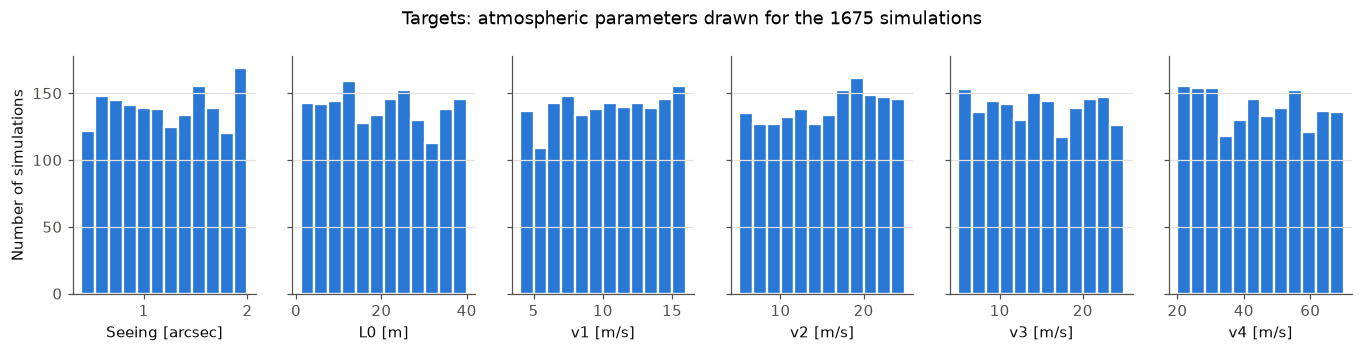

In [8]:
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8), sharey=True)
for i, ax in enumerate(axes):
    ax.hist(y[:, i], bins=12, color=C_TRAIN, edgecolor='white', linewidth=1.5)
    ax.set_xlabel(TARGET_LABELS[i])
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Number of simulations')
fig.suptitle(f'Targets: atmospheric parameters drawn for the {len(y)} simulations', y=1.03)
plt.show()

All six parameters were drawn from **uniform** distributions, so the histograms are roughly flat. With about 1500 simulations they are much smoother, but there are still gaps. Keep this in mind: 1500 examples is a **small** dataset for neural networks, and the three inputs have to carry information about six unknowns.

### 2.3 Look at the raw simulation output of one sample

Before we reduce each simulation to three numbers, let us look at what is behind them. We compare the simulations with the **best** and the **worst** seeing.

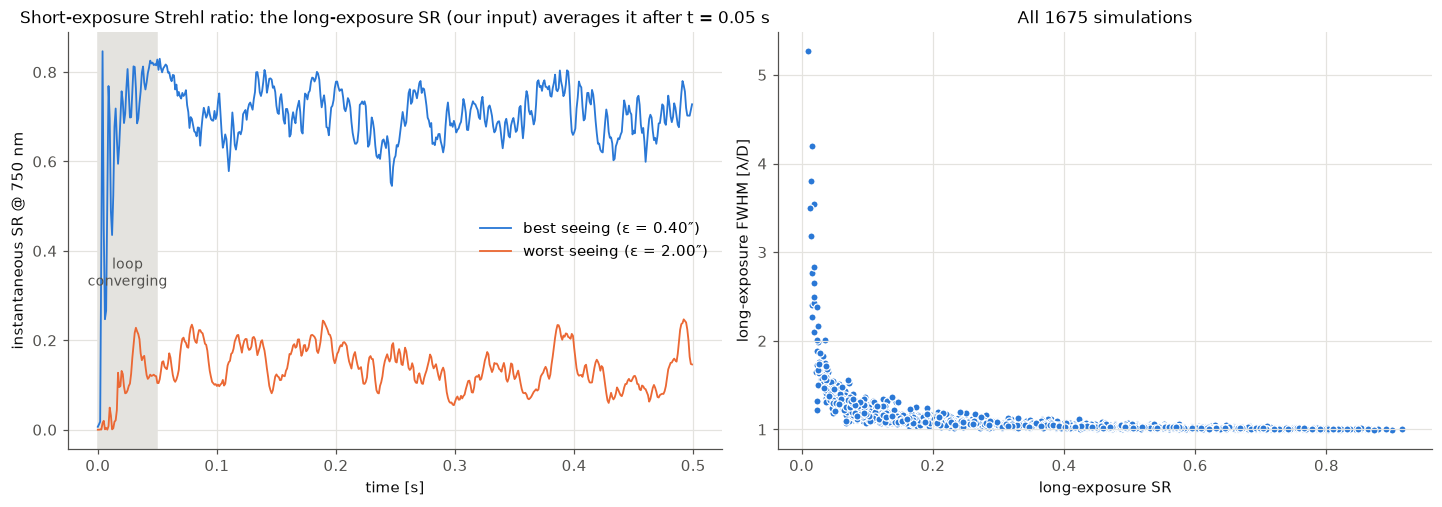

1 λ/D at 750 nm ≈ 85 mas


In [9]:
i_good, i_bad = np.argmin(y[:, 0]), np.argmax(y[:, 0])
LAMBDA_D_MAS = 750e-9 / 1.82 * 206265e3        # 1 λ/D in milliarcsec
t = np.arange(sr_ts.shape[1]) * 1e-3           # 1 kHz loop

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')

# frame-by-frame Strehl ratio: shows the loop closing and converging
for idx, color, tag in [(i_good, C_TRAIN, 'best seeing'), (i_bad, C_VAL, 'worst seeing')]:
    ax1.plot(t, sr_ts[idx], color=color, lw=1.2, label=f'{tag} (ε = {y[idx,0]:.2f}″)')
ax1.axvspan(0, 0.05, color='#e4e3df', zorder=0)
ax1.text(0.025, 0.35, 'loop\nconverging', ha='center', va='center', fontsize=9, color=C_REF)
ax1.set_xlabel('time [s]'); ax1.set_ylabel('instantaneous SR @ 750 nm'); ax1.legend(loc='center right')
ax1.set_title('Short-exposure Strehl ratio: the long-exposure SR (our input) averages it after t = 0.05 s')

# the two main inputs for all simulations
ax2.scatter(X[:, 0], X[:, 2], s=22, color=C_TRAIN, edgecolor='white', linewidth=0.8)
ax2.set_xlabel('long-exposure SR'); ax2.set_ylabel('long-exposure FWHM [λ/D]')
ax2.set_title(f'All {len(X)} simulations')
plt.show()
print(f'1 λ/D at 750 nm ≈ {LAMBDA_D_MAS:.0f} mas')

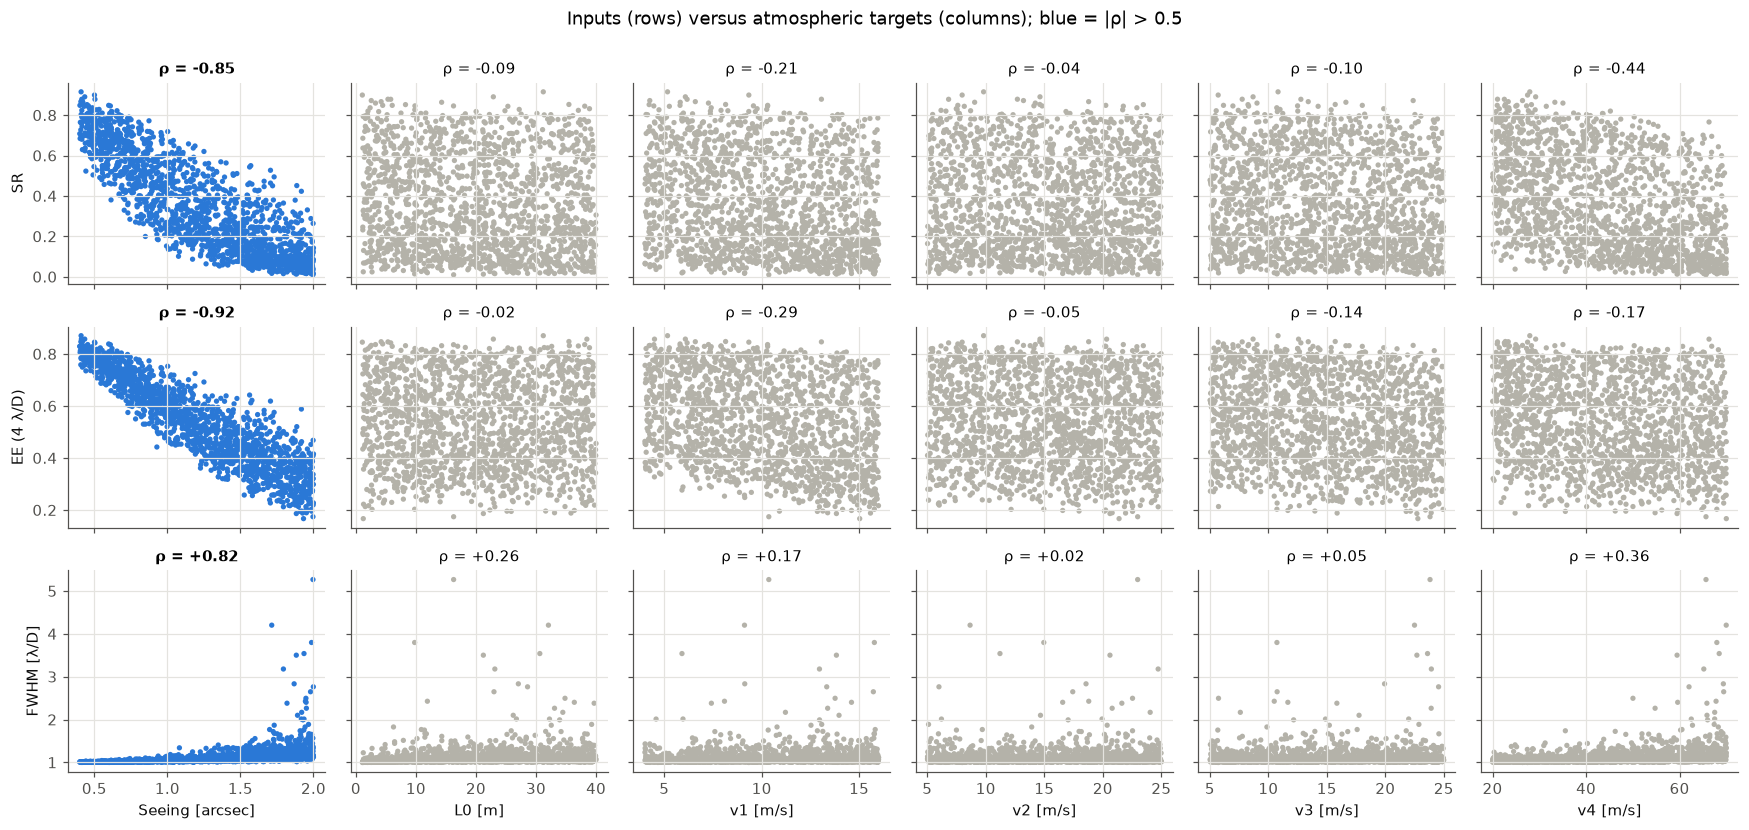

In [10]:
from scipy.stats import spearmanr

fig, axes = plt.subplots(3, 6, figsize=(16, 7.5), sharex='col', sharey='row')
for r in range(3):
    for c in range(6):
        ax = axes[r, c]
        rho = spearmanr(y[:, c], X[:, r])[0]
        strong = abs(rho) > 0.5
        ax.scatter(y[:, c], X[:, r], s=12, color=C_TRAIN if strong else '#b4b2a9', edgecolor='none')
        ax.set_title(f'ρ = {rho:+.2f}', fontsize=10, fontweight='bold' if strong else 'normal')
        if r == 2: ax.set_xlabel(TARGET_LABELS[c])
        if c == 0: ax.set_ylabel(INPUT_NAMES[r])
fig.suptitle('Inputs (rows) versus atmospheric targets (columns); blue = |ρ| > 0.5', y=1.0)
plt.tight_layout(); plt.show()

**Interpretation: this is the most important plot of the tutorial.**

- **Seeing** is strongly visible in all three inputs ($|\rho| \approx 0.9$). Worse seeing gives lower SR, lower EE and a wider PSF, as expected from the $(D/r_0)^{5/3}$ scaling. We expect the network to predict seeing well.
- **$v_1$** (the ground layer, ≈ 70 % of the turbulence) has a weak signature ($|\rho| < 0.3$). A faster ground layer gives a larger servo-lag error and so a lower SR.
- **$L_0$, $v_2$, $v_3$, $v_4$** give almost no signal. These layers carry little turbulence, and $L_0$ changes mostly tip-tilt, which the AO loop corrects well. Their effect on SR, EE and FWHM is smaller than the effect of seeing, zenith angle and noise.

We also see some scatter even in the seeing panels. Part of it comes from the **nuisance parameters**. For example, the same seeing at a larger zenith angle means more turbulence along the line of sight:

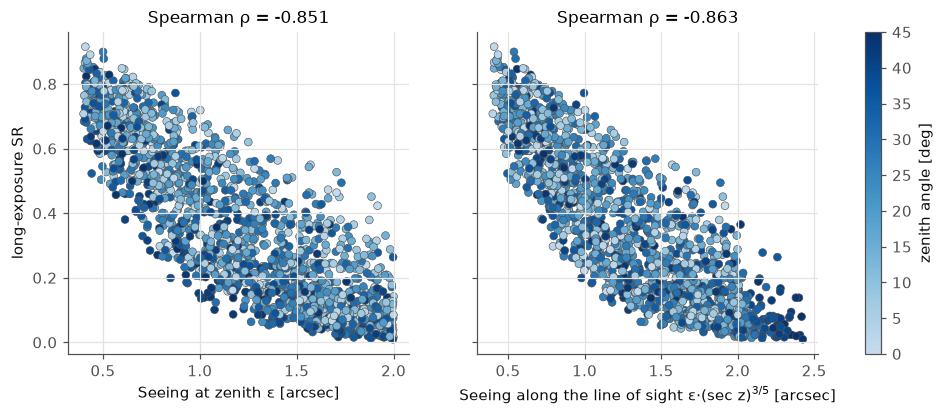

In [11]:
from matplotlib.colors import ListedColormap
zen_cmap = ListedColormap(plt.cm.Blues(np.linspace(0.25, 1, 256)))     
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
seeing_eff = y[:, 0] / np.cos(np.radians(zenith)) ** 0.6        
for ax, xval, xlabel in [(axes[0], y[:, 0], 'Seeing at zenith ε [arcsec]'),
                         (axes[1], seeing_eff, 'Seeing along the line of sight ε·(sec z)$^{3/5}$ [arcsec]')]:
    sc = ax.scatter(xval, X[:, 0], c=zenith, cmap=zen_cmap, vmin=0, vmax=45, s=26, edgecolor='#52514e', linewidth=0.4)
    ax.set_xlabel(xlabel)
    ax.set_title(f'Spearman ρ = {spearmanr(xval, X[:, 0])[0]:+.3f}')
axes[0].set_ylabel('long-exposure SR')
fig.colorbar(sc, ax=axes, label='zenith angle [deg]')
plt.show()

With the airmass correction the relation becomes tighter. Zenith angle is a hidden variable that the network does not see, and it adds "noise" to our inverse problem. 

---
## 4. Pre-processing

Neural networks train best when inputs and outputs are **numbers of order 1, centred on zero**. Our raw quantities have very different scales: SR is between 0.01 and 0.8, FWHM between 1 and 5, $L_0$ between 1 and 40 m. The squared-error loss would be dominated by the targets with large numbers (the wind speeds, $L_0$) and would almost ignore seeing.

We apply two pre-processing methods:

1. **Log transform of the inputs** ($x \to \log x$). SR spans almost two orders of magnitude and is very skewed. The log spreads the values evenly. It is also physically motivated: in the Maréchal approximation $\mathrm{SR} \approx e^{-\sigma^2}$, so $\log \mathrm{SR}$ is linear in the residual wavefront variance $\sigma^2$.
2. **Z-score standardisation** of inputs and targets: $\;x' = (x-\mu)/\sigma$.

> ⚠️ **Data leakage.** $\mu$ and $\sigma$ must be computed **on the training set only**. If we used the whole dataset, a little information about the test set would go into the model, and the test score would look better than it really is. That is why we split first (Section 5) and compute the statistics afterwards.

Here we only **look** at the effect of the log transform on the input distributions:

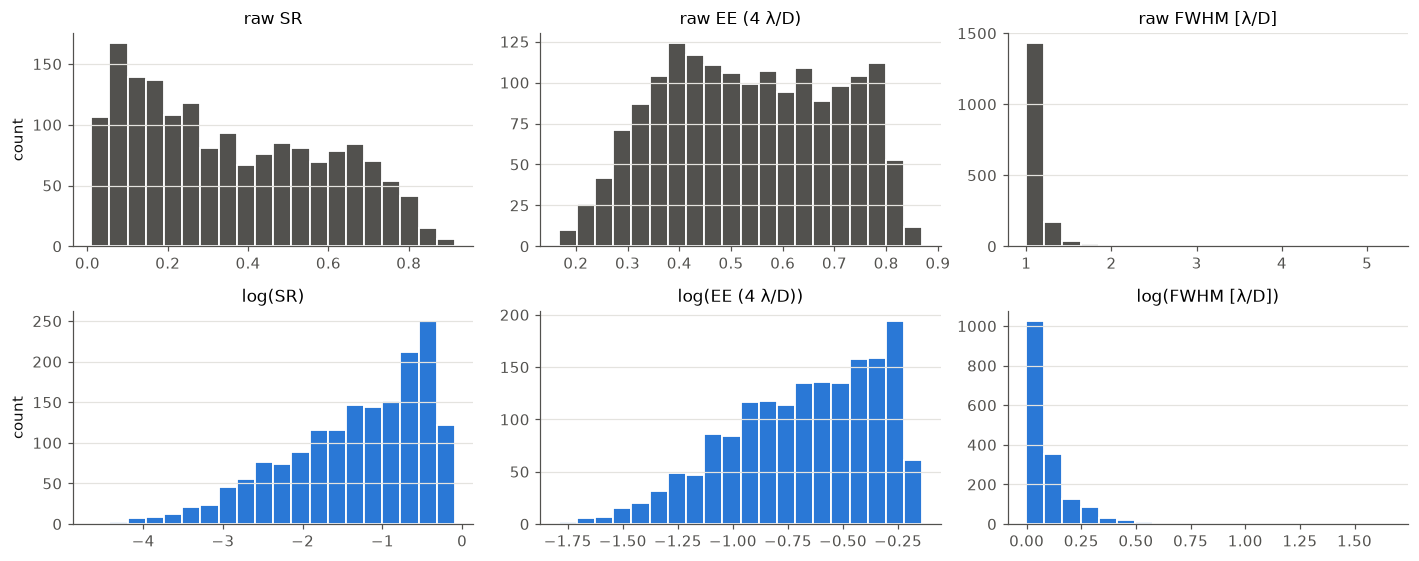

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.2))
for j in range(3):
    axes[0, j].hist(X[:, j], bins=20, color=C_REF, edgecolor='white', linewidth=1.2)
    axes[0, j].set_title(f'raw {INPUT_NAMES[j]}')
    axes[1, j].hist(np.log(X[:, j]), bins=20, color=C_TRAIN, edgecolor='white', linewidth=1.2)
    axes[1, j].set_title(f'log({INPUT_NAMES[j]})')
for ax in axes.flat: ax.grid(axis='x', visible=False)
axes[0, 0].set_ylabel('count'); axes[1, 0].set_ylabel('count')
plt.tight_layout(); plt.show()

The log spreads out the many low-SR samples, which were squeezed near 0. FWHM stays skewed even after the log, and this is physical. Whenever the AO system keeps a diffraction-limited core, the FWHM saturates at ≈ 1 $\lambda/D$. Only when the correction is poor (SR ≲ 0.05) does it jump to 2–5 $\lambda/D$. So FWHM carries information only in the bad-seeing regime, while SR and EE are informative everywhere.

## 5. Split the data: train / validation / test

We divide the N simulations into three **disjoint** sets. Each set has a different job:

| Set | Used for | Does the model learn from it? |
|---|---|---|
| **Training** | Updating the network weights (gradient descent) | Yes |
| **Validation** | Monitoring training: selecting the best epoch, tuning hyper-parameters, detecting over-fitting | Indirectly (we make choices with it) |
| **Test** | One final, honest estimate of the performance on new data | **No. Look at it only at the end** |



In [13]:
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

indices = np.arange(len(X))
train_idx, rest_idx = train_test_split(indices, test_size=VAL_FRAC + TEST_FRAC, random_state=SEED)
val_idx, test_idx   = train_test_split(rest_idx, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), random_state=SEED)
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
print(f'train: {len(train_idx)}   validation: {len(val_idx)}   test: {len(test_idx)}')

train: 1172   validation: 251   test: 252


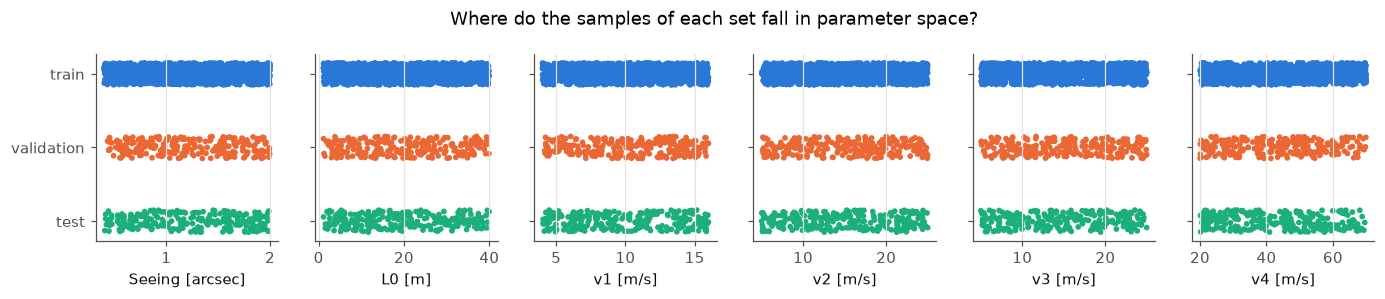

In [14]:
# Check: do the three sets cover the same parameter range? (A test value far outside the training range
# would be an extrapolation, and neural networks are bad at extrapolating.)
fig, axes = plt.subplots(1, 6, figsize=(15, 2.2), sharey=True)
for i, ax in enumerate(axes):
    for k, (idx, color, name) in enumerate([(train_idx, C_TRAIN, 'train'), (val_idx, C_VAL, 'validation'),
                                            (test_idx, C_TEST, 'test')]):
        ax.scatter(y[idx, i], np.full(len(idx), k) + np.random.uniform(-0.15, 0.15, len(idx)),
                   s=14, color=color, edgecolor='none')
    ax.set_xlabel(TARGET_LABELS[i]); ax.grid(axis='y', visible=False)
axes[0].set_yticks([0, 1, 2], ['train', 'validation', 'test']); axes[0].invert_yaxis()
fig.suptitle('Where do the samples of each set fall in parameter space?', y=1.06)
plt.show()

### 5.1 Fit the normalisation on the training set, then apply it to all sets

In [15]:
# 1) log of the inputs

X_log = np.log(X + 1e-12)

# 2) statistics from the TRAINING set only
x_mean, x_std = X_log[train_idx].mean(0), X_log[train_idx].std(0)
y_mean, y_std = y[train_idx].mean(0),     y[train_idx].std(0)
x_std[x_std == 0] = 1; y_std[y_std == 0] = 1

# 3) the same transformation for every set
Xn = (X_log - x_mean) / x_std
yn = (y - y_mean) / y_std

def denormalize_y(yn_):                    # back to physical units (used at test time)
    return yn_ * y_std + y_mean

print('normalised train inputs : mean', Xn[train_idx].mean(0).round(3), ' std', Xn[train_idx].std(0).round(3))
print('normalised train targets: mean', yn[train_idx].mean(0).round(3), ' std', yn[train_idx].std(0).round(3))
print('normalised test  targets: mean', yn[test_idx].mean(0).round(2), '  (not exactly 0: expected, and correct)')

normalised train inputs : mean [-0.  0. -0.]  std [1. 1. 1.]
normalised train targets: mean [ 0.  0. -0. -0.  0. -0.]  std [1. 1. 1. 1. 1. 1.]
normalised test  targets: mean [ 0.06 -0.08 -0.11  0.01  0.03 -0.13]   (not exactly 0: expected, and correct)


### 5.2 PyTorch `Dataset` and `DataLoader`

PyTorch reads the data through a `DataLoader`. It gives the network **mini-batches** of samples, and it can shuffle the training set at each epoch (shuffling makes stochastic gradient descent work better). 

In [16]:
BATCH_SIZE = 56

def make_loader(idx, shuffle):
    ds = TensorDataset(torch.tensor(Xn[idx]), torch.tensor(yn[idx]))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0)

train_loader = make_loader(train_idx, shuffle=True)
val_loader   = make_loader(val_idx,   shuffle=False)
test_loader  = make_loader(test_idx,  shuffle=False)

xb, yb = next(iter(train_loader))
print('one batch -> inputs', tuple(xb.shape), ' targets', tuple(yb.shape))

one batch -> inputs (56, 3)  targets (56, 6)


## 6. The neural network

We use a **fully-connected (dense) neural network**, also called a multi-layer perceptron (MLP).

```
 input (3)            hidden 1 (1024)        hidden 2 (16)          output (6)
 log SR   ─┐                                                       ┌─ seeing
 log EE   ─┼─► Linear ─► ReLU ─────► Linear ─► ReLU ─────► Linear ─┼─ L0
 log FWHM ─┘   3×1024+1024           1024×16+16            16×6+6   └─ v1 v2 v3 v4
```

- Each **Linear** layer computes $\mathbf{h} = W\mathbf{x} + \mathbf{b}$. The weights $W$ and biases $\mathbf{b}$ are the parameters that training adjusts.
- **ReLU** $(\max(0, h))$ is the non-linearity. Without it, the stack of layers would be one linear regression. With it, the network can approximate non-linear relations, like SR ∝ $e^{-(D/r_0)^{5/3}}$.
- The **output layer has no activation**, because this is **regression**: the outputs are any real numbers (normalised physical quantities).
- The 6 outputs share the same hidden layers (**multi-output regression**). The network learns one common representation of "the state of the turbulence" and reads all the parameters from it.

**Loss function:** mean squared error on the *normalised* targets, averaged over the 6 parameters:
$$\mathcal{L} = \frac{1}{6N}\sum_{n=1}^{N}\sum_{k=1}^{6}\left(\hat y'_{nk} - y'_{nk}\right)^2 .$$
Because the targets are standardised, **a loss of 1.0 means "no better than always predicting the mean"**. This is our baseline.

**Optimiser:** Adam, learning rate $10^{-3}$. It is an adaptive version of stochastic gradient descent.

In [17]:
N_INPUTS   = 3      # log SR, log EE, log FWHM
N_HIDDEN_1 = 128 #  1024   # neurons in the first hidden layer
N_HIDDEN_2 = 16     # neurons in the second hidden layer
N_OUTPUTS  = 6      # seeing, L0, v1, v2, v3, v4

class DenseNN(nn.Module):

    def __init__(self, neurons_first_hidden_layers=N_HIDDEN_1):
        super().__init__()                   
        self.fc1 = nn.Linear(N_INPUTS, neurons_first_hidden_layers)   
        self.fc2 = nn.Linear(neurons_first_hidden_layers, N_HIDDEN_2)  
        self.fc3 = nn.Linear(N_HIDDEN_2, N_OUTPUTS)                   

        self.relu = nn.ReLU()                  

    def forward(self, x): 

        h1 = self.relu(self.fc1(x))            
        h2 = self.relu(self.fc2(h1))         
        y_pred = self.fc3(h2)                 

        return y_pred

torch.manual_seed(SEED)                   

model = DenseNN().to(device)               
criterion = nn.MSELoss()                  
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)   

print(model)   

DenseNN(
  (fc1): Linear(in_features=3, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=6, bias=True)
  (relu): ReLU()
)


---
## 7. Training and validation

Each **epoch** is one full pass over the training set:

1. **Training phase** (`model.train()`): for every mini-batch
   - *forward pass*: compute the predictions and the loss,
   - *backward pass*: `loss.backward()` computes $\partial\mathcal{L}/\partial W$ for every weight (back-propagation),
   - *update*: `optimizer.step()` moves the weights a small step against the gradient.
2. **Validation phase** (`model.eval()`, `torch.no_grad()`): compute the loss on the validation set **without** changing the weights.


ANIMATION: https://www.youtube.com/watch?v=EOEPpUNJ7xc&pp=ygU4YW5pbWF0aW9uIGZvcndhcmQgcGFzcyBhbmQgYmFja3dhcmQgcGFzcyBuZXVyYWwgbmV0d29ya3M%3D



We keep the weights of the epoch with the **lowest validation loss** (*checkpointing on the best validation loss*). This is a simple form of **early stopping**: if the model starts to over-fit later, we still keep the best version.

### 7.1 Pretrained model or train your own?

To save time during the school, **a pretrained model is loaded by default**. It was trained with exactly the code below: same data, same split, same settings. Read the training function carefully anyway, because it is the heart of the tutorial. When you want to experiment (Section 11), switch to training it yourself.

The next cell only **defines** three functions:

| Function | What it does |
|---|---|
| `train_model(epochs, save_path=None)` | Runs the training loop and restores the best-validation weights. If `save_path` is given, it also saves the result there |
| `save_checkpoint(path, ...)` | Saves the weights **plus** the normalisation statistics, the data split and the learning curves |
| `load_pretrained_model(path)` | Loads a saved model. It first checks that the dataset and split are the same as when the model was trained (otherwise the "test" set might contain training samples) |

In [18]:
PRETRAINED_PATH = PROJECT_ROOT / 'pretrained_models' / 'dnn_atmo_retrieval_70_15_15.pt'
EPOCHS = 1500

def run_epoch(loader, train):
    # One pass over a loader. Returns the sample-weighted mean loss.
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = criterion(model(xb), yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(xb); n += len(xb)
    return total / n


def save_checkpoint(path, history, best_epoch, best_val):
    # Everything needed to reuse the model later, not only the weights.
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        'model': {k: v.cpu() for k, v in model.state_dict().items()},
        'model_kwargs': {'neurons_first_hidden_layers': model.fc1.out_features},
        'epoch': best_epoch, 'best_val_loss': best_val, 'history': history,
        'normalizer': {'input_log': True, 'input_mean': x_mean, 'input_std': x_std,
                       'output_mean': y_mean, 'output_std': y_std},
        'split': {'seed': SEED, 'train': train_idx, 'val': val_idx, 'test': test_idx},
        'samples': ids.tolist(),
        'input_names': INPUT_NAMES, 'target_names': TARGET_NAMES, 'target_units': TARGET_UNITS,
    }, path)
    print('Model saved to', path)



def train_model(epochs=EPOCHS, save_path=None):
    # Train `model`, keep the weights with the lowest validation loss, optionally save them.
    history = {'train': [], 'val': []}
    best_val, best_epoch, best_state = float('inf'), -1, None

    for epoch in range(epochs):
        train_loss = run_epoch(train_loader, train=True)
        val_loss   = run_epoch(val_loader,   train=False)
        history['train'].append(train_loss); history['val'].append(val_loss)

        if val_loss < best_val:                                     # checkpoint on best validation loss
            best_val, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if epoch % 30 == 0 or epoch == epochs - 1:
            print(f'epoch {epoch+1:3d}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f}')

    model.load_state_dict(best_state)
    print(f'\nBest validation loss {best_val:.4f} at epoch {best_epoch+1}: these weights are restored.')

    if save_path is not None:
        save_checkpoint(save_path, history, best_epoch, best_val)
    return history, best_epoch, best_val



def load_pretrained_model(path=PRETRAINED_PATH):
    # Load saved weights into `model`, after checking that data, split and normalisation match.
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'{path} not found. '
                                'Train your own model (Option B in the next cell).')
    ckpt = torch.load(path, map_location=device, weights_only=False)

    norm = ckpt['normalizer']
    checks = {
        'same simulations': list(ckpt['samples']) == ids.tolist(),
        'same train/val/test split': all(np.array_equal(ckpt['split'][k], idx) for k, idx in
                                         [('train', train_idx), ('val', val_idx), ('test', test_idx)]),
        'same normalisation': all(np.allclose(norm[k], v) for k, v in
                                  [('input_mean', x_mean), ('input_std', x_std),
                                   ('output_mean', y_mean), ('output_std', y_std)]),
    }
    for name, ok in checks.items():
        print(f'  {"✔" if ok else "✘"} {name}')
    if not all(checks.values()):
        raise RuntimeError('The dataset or the split changed since this model was trained, so its test set '
                           'is not guaranteed to be unseen. Train a new model (Option B).')

    model.load_state_dict(ckpt['model'])
    print(f'Loaded {path.name}: best epoch {ckpt["epoch"]+1}, best validation loss {ckpt["best_val_loss"]:.4f}')
    return ckpt['history'], ckpt['epoch'], ckpt['best_val_loss']

### 7.2 Get a trained model

- **Option A (default):** load the pretrained model.
- **Option B:** train the model yourself. Comment out Option A and uncomment **one** of the two Option B lines. Training takes about a minute on a GPU and a few minutes on a CPU.

In [19]:
# ▶ Option A: load the pretrained model (default)
# history, best_epoch, best_val = load_pretrained_model(PRETRAINED_PATH)

# ▶ Option B: train the model yourself (uncomment ONE line, and comment out Option A)
# history, best_epoch, best_val = train_model(epochs=EPOCHS)                              
history, best_epoch, best_val = train_model(epochs=EPOCHS, save_path=PRETRAINED_PATH)   

# sanity check: recompute the validation loss of the model that is now in memory
print(f'Validation loss of the model in memory: {run_epoch(val_loader, train=False):.4f}')

epoch   1/1500 | train loss 0.9768 | val loss 0.9069
epoch  31/1500 | train loss 0.6402 | val loss 0.6201
epoch  61/1500 | train loss 0.6148 | val loss 0.5976
epoch  91/1500 | train loss 0.6065 | val loss 0.5908
epoch 121/1500 | train loss 0.6013 | val loss 0.5925
epoch 151/1500 | train loss 0.5986 | val loss 0.5873
epoch 181/1500 | train loss 0.5926 | val loss 0.5884
epoch 211/1500 | train loss 0.5909 | val loss 0.5849
epoch 241/1500 | train loss 0.5887 | val loss 0.5835
epoch 271/1500 | train loss 0.5868 | val loss 0.5850
epoch 301/1500 | train loss 0.5839 | val loss 0.5851
epoch 331/1500 | train loss 0.5842 | val loss 0.5842
epoch 361/1500 | train loss 0.5810 | val loss 0.5821
epoch 391/1500 | train loss 0.5791 | val loss 0.5871
epoch 421/1500 | train loss 0.5781 | val loss 0.5847
epoch 451/1500 | train loss 0.5756 | val loss 0.5828
epoch 481/1500 | train loss 0.5780 | val loss 0.5800
epoch 511/1500 | train loss 0.5740 | val loss 0.5866
epoch 541/1500 | train loss 0.5744 | val loss 

In [20]:
# val, train = np.array(history['val']), np.array(history['train'])
# b = val.argmin()
# print(f'lowest validation loss : {val[b]:.4f} at epoch {b+1}   <- the one in the sentence')
# print(f'training loss at that epoch: {train[b]:.4f}')
# print(f'lowest training loss   : {train.min():.4f} at epoch {train.argmin()+1}   (not used to choose the model)')
# print(f'last epoch             : train {train[-1]:.4f}, val {val[-1]:.4f}')

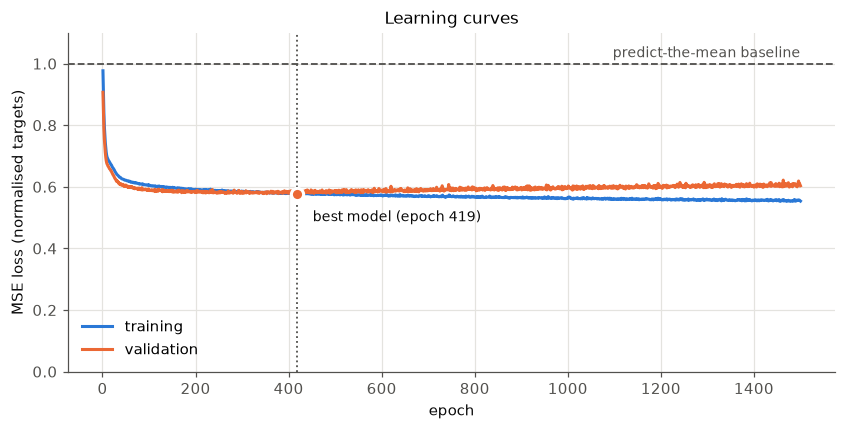

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
ep = np.arange(1, len(history['train']) + 1)
ax.plot(ep, history['train'], color=C_TRAIN, label='training')
ax.plot(ep, history['val'],   color=C_VAL,   label='validation')
ax.axhline(1.0, color=C_REF, ls='--', lw=1.2)
ax.text(ep[-1], 1.01, 'predict-the-mean baseline', va='bottom', ha='right', color=C_REF, fontsize=9)
ax.axvline(best_epoch + 1, color=C_REF, ls=':', lw=1.2)
ax.plot(best_epoch + 1, best_val, 'o', ms=8, color=C_VAL, markeredgecolor='white', markeredgewidth=2)
ax.annotate(f'best model (epoch {best_epoch+1})', (best_epoch + 1, best_val), xytext=(10, -18),
            textcoords='offset points', fontsize=9, color='#0b0b0b')
ax.set_ylim(0, 1.1); ax.set_xlabel('epoch'); ax.set_ylabel('MSE loss (normalised targets)')
ax.set_title('Learning curves'); ax.legend(loc='lower left')
plt.show()

**How to read learning curves**

- **First few tens of epochs:** both curves fall together, from 1.0 (the baseline) to ≈ 0.7. The network learns the part of the problem that *generalises*: mostly the seeing.
- **Why not closer to 0?** The loss is an *average over 6 parameters*. If seeing were predicted perfectly (error ≈ 0) and the other 5 parameters stayed at the baseline (error ≈ 1), the average would be ≈ 5/6 ≈ 0.83. A validation loss of ≈ 0.7 is therefore about what we can expect. The limit comes from the **information in the inputs**, not from the network.
- **After the minimum**, the training loss keeps falling but the validation loss slowly **rises**. This is **over-fitting**: the 20 000 parameters start to memorise the particular noise of the 70 training samples (for example, accidental correlations between SR and $v_2$). These do not generalise to new data. The best-epoch checkpoint (dot) protects us: we keep the weights from before over-fitting started.
- The validation set has only 15 samples, so its curve is noisy. Do not over-interpret single spikes. TO BE MODIFIED ACCORDING TO BETTER DATASET.

---
## 8. Evaluation on the test set

Now, for the first and only time, we use the **test set**: 15 simulations that were not used for training or for choosing the model. We convert the predictions back to **physical units** and compute, for each parameter:

- **MAE**: mean absolute error, in physical units.
- **Baseline MAE**: the MAE if we always predict the *training-set mean*. A useful model must be clearly better than this.
- **$R^2$**: coefficient of determination. 1 is a perfect prediction, 0 is no better than the mean, and < 0 is worse than the mean.

In [22]:
model.eval()
with torch.no_grad():
    pred_test = denormalize_y(model(torch.tensor(Xn[test_idx]).to(device)).cpu().numpy())
true_test = y[test_idx]

def r2(t, p):
    return 1 - ((t - p) ** 2).sum(0) / ((t - t.mean(0)) ** 2).sum(0)

mae      = np.abs(pred_test - true_test).mean(0)
mae_base = np.abs(y_mean - true_test).mean(0)
results = pd.DataFrame({
    'unit': TARGET_UNITS,
    'MAE (NN)': mae,
    'MAE (baseline: mean)': mae_base,
    'improvement': 1 - mae / mae_base,
    'R²': r2(true_test, pred_test),
}, index=TARGET_NAMES)
results.style.format({'MAE (NN)': '{:.3f}', 'MAE (baseline: mean)': '{:.3f}',
                      'improvement': '{:+.0%}', 'R²': '{:+.2f}'})

,unit,MAE (NN),MAE (baseline: mean),improvement,R²
Seeing,arcsec,0.143,0.420,+66%,+0.85
L0,m,7.738,9.885,+22%,+0.36
v1,m/s,2.856,3.213,+11%,+0.15
v2,m/s,4.961,5.045,+2%,+0.00
v3,m/s,4.744,4.933,+4%,+0.06
v4,m/s,3.303,12.480,+74%,+0.92


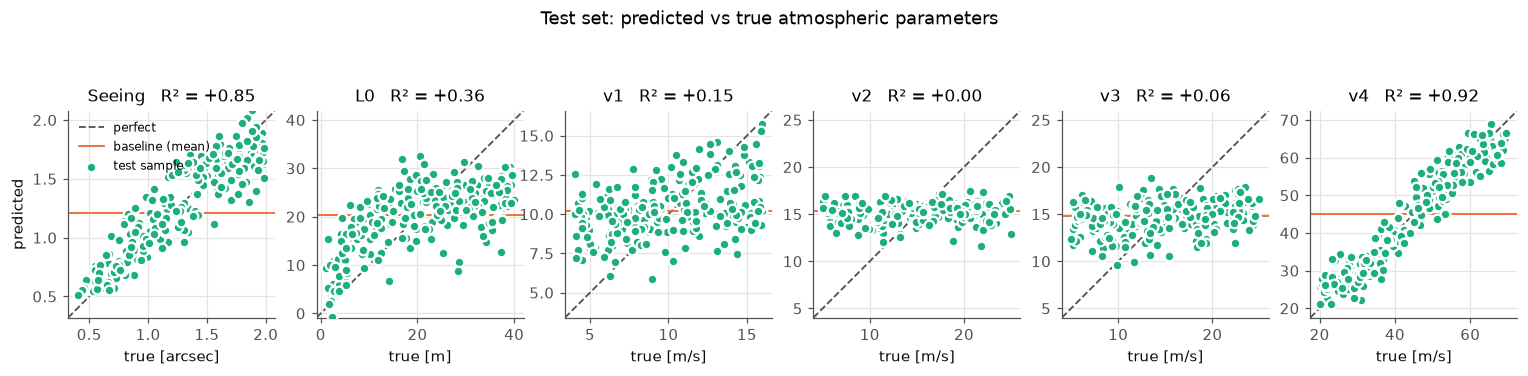

In [23]:
fig, axes = plt.subplots(1, 6, figsize=(17, 3.4))
r2_all = r2(true_test, pred_test)
for i, ax in enumerate(axes):
    lo, hi = y[:, i].min(), y[:, i].max()
    pad = 0.05 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color=C_REF, ls='--', lw=1.2, label='perfect')
    ax.axhline(y_mean[i], color=C_VAL, lw=1.2, label='baseline (mean)')
    ax.scatter(true_test[:, i], pred_test[:, i], s=40, color=C_TEST, edgecolor='white', linewidth=1.5, zorder=3,
               label='test sample')
    ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad); ax.set_aspect('equal')
    ax.set_title(f'{TARGET_NAMES[i]}   R² = {r2_all[i]:+.2f}')
    ax.set_xlabel(f'true [{TARGET_UNITS[i]}]')
axes[0].set_ylabel('predicted')
axes[0].legend(loc='upper left', fontsize=8)
fig.suptitle('Test set: predicted vs true atmospheric parameters', y=1.04)
plt.show()

**Interpretation**

- **Seeing** is retrieved well: the points follow the 1:1 line, $R^2 \approx 0.9$, and the mean absolute error is ≈ 0.1″. That is about 3× better than the baseline, and comparable to the typical disagreement between two seeing monitors. From three numbers that every AO system produces, the network gives a useful seeing estimate *along the line of sight of the science target*.
- For **$L_0$ and the wind speeds** the predictions do **not** follow the 1:1 line. They scatter around the horizontal "mean" line, and $R^2$ is close to 0 (slightly positive or negative). With only 15 test samples, values like ±0.2 are consistent with zero. The scatter of the predictions is the over-fitting noise we saw in the learning curves: the network produces some variation, but it is not related to the true values.
- The 6-output model still performs well on seeing: the shared hidden layers let each output use what it needs.
- This is not a failure of machine learning. The **inputs do not contain the information**, as we saw in Section 3. This is the most important lesson of the tutorial: *explore your data before you train, and always compare with a baseline.*

Let us look more closely at the seeing errors. Is there structure in the residuals?

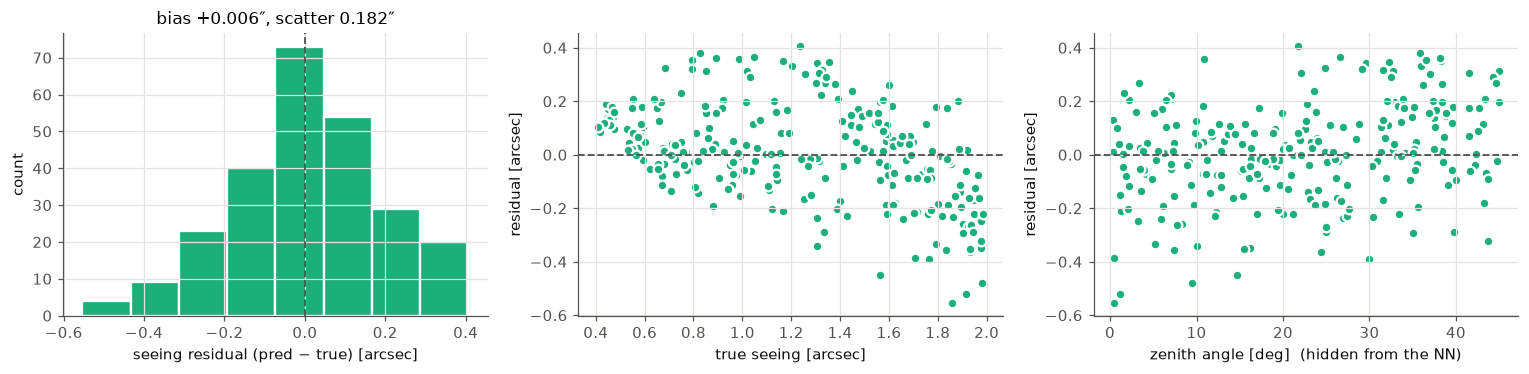

In [24]:
res = pred_test[:, 0] - true_test[:, 0]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(res, bins=8, color=C_TEST, edgecolor='white', linewidth=1.5)
axes[0].axvline(0, color=C_REF, ls='--', lw=1.2)
axes[0].set_xlabel('seeing residual (pred − true) [arcsec]'); axes[0].set_ylabel('count')
axes[0].set_title(f'bias {res.mean():+.3f}″, scatter {res.std():.3f}″')
for ax, xval, xlabel in [(axes[1], true_test[:, 0], 'true seeing [arcsec]'),
                         (axes[2], zenith[test_idx], 'zenith angle [deg]  (hidden from the NN)')]:
    ax.axhline(0, color=C_REF, ls='--', lw=1.2)
    ax.scatter(xval, res, s=40, color=C_TEST, edgecolor='white', linewidth=1.5)
    ax.set_xlabel(xlabel); ax.set_ylabel('residual [arcsec]')
plt.tight_layout(); plt.show()

Look for patterns:
- A trend of the residual with **zenith angle** would show that the network sees the *line-of-sight* seeing but not the zenith seeing. It cannot know the difference because $z$ is not an input.
- Larger errors at **large seeing** are expected. When the correction is poor, SR changes little with seeing (SR is already close to 0), so the inputs are less sensitive to it.

With only 15 test points these trends are only hints. A bigger dataset would make them clear.

---
## 9. Saving and reusing a model

A model is only useful if we can use it again later. `save_checkpoint()` (Section 7) stores the weights **together with the normalisation statistics**. Without $\mu$ and $\sigma$ nobody can pre-process new data in the same way, and the predictions would be meaningless. It also stores the split and the learning curves, so that the results can be reproduced. Let us look inside the pretrained checkpoint:

In [25]:
ckpt = torch.load(PRETRAINED_PATH, map_location='cpu', weights_only=False)
for key, value in ckpt.items():
    summary = f'dict with keys {list(value)}' if isinstance(value, dict) else \
              f'list of {len(value)} items' if isinstance(value, list) else value
    print(f'{key:14s}: {summary}')

# If you trained your own model (Option B), you can keep it in a file of your own:
# save_checkpoint(WORKFLOW_ROOT / 'outputs' / 'notebook' / 'my_model.pt', history, best_epoch, best_val)

model         : dict with keys ['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias', 'fc3.weight', 'fc3.bias']
model_kwargs  : dict with keys ['neurons_first_hidden_layers']
epoch         : 418
best_val_loss : 0.5775759457591996
history       : dict with keys ['train', 'val']
normalizer    : dict with keys ['input_log', 'input_mean', 'input_std', 'output_mean', 'output_std']
split         : dict with keys ['seed', 'train', 'val', 'test']
samples       : list of 1675 items
input_names   : list of 3 items
target_names  : list of 6 items
target_units  : list of 6 items


### 9.1 Use the saved model: inference on a "new observation"

This is how the model would be used at the telescope. Load the checkpoint, pre-process the three measured values **with the stored statistics**, predict, and convert back to physical units. It uses only the file: nothing from the notebook's memory.

In [26]:
checkpoint_path = PRETRAINED_PATH            # or the path of your own saved model
ckpt = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
retrieval_model = DenseNN(**ckpt['model_kwargs']); retrieval_model.load_state_dict(ckpt['model']); retrieval_model.eval()
norm = ckpt['normalizer']

def retrieve_atmosphere(sr, ee, fwhm):
    x = (np.log(np.array([sr, ee, fwhm], dtype=np.float32) + 1e-12) - norm['input_mean']) / norm['input_std']
    with torch.no_grad():
        out = retrieval_model(torch.tensor(x)[None]).numpy()[0]
    return out * norm['output_std'] + norm['output_mean']

k = test_idx[5]                                     # pretend this test simulation is a new observation
estimate = retrieve_atmosphere(*X[k])
print(f'Measured: SR = {X[k,0]:.3f}, EE = {X[k,1]:.3f}, FWHM = {X[k,2]:.2f} λ/D\n')
print(pd.DataFrame({'true': y[k], 'retrieved': estimate}, index=TARGET_LABELS).round(2))

Measured: SR = 0.653, EE = 0.793, FWHM = 1.02 λ/D

                      true  retrieved
Seeing [arcsec]   0.480000   0.570000
L0 [m]           16.290001  26.830000
v1 [m/s]         13.080000   7.620000
v2 [m/s]         10.890000  13.510000
v3 [m/s]          8.350000  11.360000
v4 [m/s]         61.529999  56.310001


---
## 10. Exercises

1. **Hyper-parameters.** Switch to Option B in Section 7.2 (train yourself), then change `EPOCHS`, the learning rate, `BATCH_SIZE` or `neurons_first_hidden_layers`. Do you get a better validation loss? Is the model over-fitting? (Tip: try a much smaller network, e.g. 32 neurons.)
2. **Add a known quantity.** Add the zenith angle (always known at the telescope) and/or the NGS magnitude as extra inputs. You need to change the first layer to `nn.Linear(4, …)`. Does the seeing retrieval improve? Compare the residual-vs-zenith plot.
3. **Predict only what is possible.** Train a network with a single output (seeing), or with (seeing, $v_1$). Is it better than the 6-output model?
4. **Use richer inputs.** Three scalars are a strong compression. `comm_rms` contains the RMS of the DM commands of each mode (400 values; the full command time series was dropped to keep the dataset small). The *time series* (`sr_ts`, `psfee_ts`, `psffwhm_ts`, 500 frames each) contain **temporal** information, and temporal information is where wind speed lives. Which input would you use to retrieve $v_1…v_4$? Why is it hard to learn from 400 inputs with a dataset of this size?
5. **Cross-validation.** With a small test set, the score depends on the random split. Repeat the split with different seeds (or use k-fold cross-validation) and report the mean and scatter of $R^2$ for seeing.
6. **Run the production pipeline.** From `ml_workflow/`, run `python main.py` (Hydra). Compare its config (`configs/config.yaml`) with the choices made in this notebook: split fractions, epochs, input normalisation. Where are the normalisation statistics computed in `train.py`, and is there a risk of data leakage?